# Sistema mecánico de apoyo al análisis de oro

Este notebook evalúa reglas observables sobre datos OHLCV y presenta sus condiciones y motivos. **No envía órdenes, no garantiza resultados ni sustituye la verificación del instrumento y los costos del bróker.**

La configuración inicial combina contexto H1 con señales M15. Es un enfoque **intradía o de corto plazo**, no una estrategia swing de varios días. Los marcos pueden configurarse; para adaptar el análisis a swings de varios días se puede usar H4 para el contexto y confirmar que la fuente proporcione historia suficiente. El artículo de Axi ilustra rupturas analizadas en H4, pero no prescribe los valores de stop, objetivo ni riesgo usados aquí.

Los resultados históricos dependen de la calidad y disponibilidad de la fuente. La salida describe condiciones observadas; no afirma qué hará después el precio.

## 1. Objetivo, estilo operativo y limitaciones

La estrategia busca identificar rupturas M15 en la dirección de una tendencia H1, con RSI como filtro y Bandas de Bollinger como contexto de volatilidad. Toda decisión se calcula al cierre de la vela; una entrada simulada ocurre, como mínimo, en la apertura de la siguiente.

`GC=F` es el contrato de futuros de oro de Yahoo Finance: **no es necesariamente el CFD XAUUSD de tu bróker**. Los horarios de sesión son referencias, no el horario oficial de negociación del instrumento. Verifica por separado símbolo, zona horaria, especificación del contrato y horario del bróker.

yfinance ofrece historia intradía limitada: M15 suele estar disponible aproximadamente para los últimos 60 días; el máximo para intervalos intradía H1 suele ser 730 días, sujeto a cambios de Yahoo/yfinance. Este cuaderno solicita esos límites y reporta las fechas realmente disponibles; no extrapola ni presenta una prueba de varios años si los datos no existen. No se consultan ni inventan noticias o datos macroeconómicos.

## 2. Glosario y horarios de sesión UTC−6

### Swing trading y estructura
El swing trading intenta capturar movimientos que suelen durar desde varias horas hasta varios días; una operación puede atravesar más de una sesión. En el trading intradía normalmente se abre y se cierra dentro del mismo día. La combinación H1/M15 de este cuaderno es intradía/corto plazo, no swing de varios días. Para una estrategia swing se pueden configurar marcos mayores, por ejemplo H4 para analizar rupturas.

Un **swing high** o **swing low** es un máximo o mínimo local usado para describir estructura. Aquí se exige que el pivote sea extremo frente a un número configurable de velas a izquierda y derecha. Solo queda confirmado después del cierre de todas las velas derechas requeridas; no se usa en decisiones anteriores a ese momento.

### Marcos temporales, velas y periodos
- **H1**: cada vela representa una hora. **M15**: cada vela representa 15 minutos.
- Una vela resume un intervalo: apertura (Open), máximo (High), mínimo (Low) y cierre (Close). El cuerpo representa la diferencia entre apertura y cierre; las mechas llegan a los máximos y mínimos. El cierre se conoce únicamente al terminar el intervalo.
- **N periodos** significa N velas, no N minutos. Veinte velas M15 equivalen a cinco horas de velas disponibles; veinte velas H1 equivalen a veinte horas. Una comparación con las N velas anteriores excluye la vela actual.
- Solo se usan velas cerradas. La marca temporal publicada por Yahoo se interpreta como inicio de intervalo y se suma la duración para obtener el cierre; las velas cuyo cierre aún no ocurrió se descartan.

### Indicadores y costos
- **Bandas de Bollinger**: media central (por defecto 20 periodos) y bandas normalmente a dos desviaciones estándar. Contracción puede acompañar menor volatilidad y expansión movimientos más amplios; las bandas no indican dirección. Aquí se muestra el ancho y su cambio. Por defecto es contexto; exigir expansión es opcional.
- **Spread**: diferencia entre precio Ask (compra) y Bid (venta), un costo. OHLC de yfinance normalmente no contiene el spread histórico Bid/Ask del bróker. No se inventa ni se aproxima usando High−Low: configura una estimación propia en unidades de precio o carga Bid/Ask de otra fuente. Sin ninguna de esas fuentes, el filtro de seguridad devuelve `NO_OPERAR`.
- **Look-ahead bias**: uso de información que no estaba disponible al decidir, como el cierre de una vela aún abierta o un swing confirmado con velas futuras antes de su confirmación. Se evita fechando decisiones al cierre, entradas en la apertura siguiente, swings en su hora de confirmación y alineando H1 con la última vela H1 ya cerrada.
- **ATR (Average True Range)** mide volatilidad, no dirección. True Range es el máximo de High−Low, |High−cierre anterior| y |Low−cierre anterior|. ATR(14) resume los rangos recientes; puede ayudar a definir márgenes, pero no es señal de compra/venta por sí mismo.

### Ventanas habituales de Forex (referencia)

| Sesión | Horario local de referencia | Aproximación UTC−6 |
|---|---|---|
| Asia/Tokio | 09:00–18:00 Tokio | 18:00 del día anterior–03:00 |
| Londres | 08:00–17:00 Londres | 02:00–11:00 estándar; 01:00–10:00 verano |
| Nueva York | 08:00–17:00 Nueva York | 07:00–16:00 estándar; 06:00–15:00 verano |
| Primera mitad de Nueva York | 08:00–12:00 Nueva York | 07:00–11:00 estándar; 06:00–10:00 verano |

El código usa `Asia/Tokyo`, `Europe/London`, `America/New_York` y `America/El_Salvador` mediante `zoneinfo`; no fija conversiones Londres/NY a UTC−6 todo el año. Londres y Nueva York cambian al horario de verano en fechas distintas, por lo que algunas semanas sus conversiones combinan horarios distintos. Japón no usa horario de verano. Las sesiones son filtros configurables y no equivalen necesariamente al horario de negociación de XAUUSD en cada bróker.

## 3. Instalación e importaciones

Si falta alguna dependencia, descomenta y ejecuta la celda de instalación en tu entorno. La instalación no se ejecuta automáticamente.

In [1]:
# %pip install yfinance pandas numpy matplotlib
from __future__ import annotations

from datetime import datetime, time, timedelta
from pathlib import Path
from zoneinfo import ZoneInfo, ZoneInfoNotFoundError
import math
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

try:
    TZ_TOKYO = ZoneInfo('Asia/Tokyo')
    TZ_LONDON = ZoneInfo('Europe/London')
    TZ_NEW_YORK = ZoneInfo('America/New_York')
    TZ_LOCAL = ZoneInfo('America/El_Salvador')
except ZoneInfoNotFoundError as exc:
    raise RuntimeError('No están disponibles las zonas IANA requeridas. En Windows instala tzdata: %pip install tzdata') from exc

pd.set_option('display.max_colwidth', 120)
plt.style.use('seaborn-v0_8-whitegrid')
print('Dependencias y zonas horarias cargadas.')

Dependencias y zonas horarias cargadas.


## 4. Parámetros configurables

Los costos se expresan en unidades de precio del ticker, no en dinero de la cuenta. No se configura un spread ficticio: selecciona una estimación propia o un CSV Bid/Ask antes de habilitar señales operables.

In [2]:
# Fuente e intervalos: intradía de Yahoo tiene límites que pueden cambiar.
TICKER = 'GC=F'
M15_PERIOD = '60d'       # Yahoo suele limitar M15 a ~60 días
H1_PERIOD = '730d'       # Máximo intradía H1 habitual de Yahoo; verificar vigente
SIGNAL_INTERVAL = '15m'
CONTEXT_INTERVAL = '1h'

# Reglas de indicadores
BREAKOUT_LOOKBACK = 20
RSI_PERIOD = 14
RSI_BUY_MAX = 70.0
RSI_SELL_MIN = 30.0
BB_PERIOD = 20
BB_STD = 2.0
REQUIRE_BB_EXPANSION = False
ATR_PERIOD = 14
MA_FAST = 10
MA_SLOW = 20

# Pivote confirmado: número de velas a cada lado (incluye velas futuras para confirmar).
SWING_LEFT = 2
SWING_RIGHT = 2

# Filtros de sesión. La operativa usa Londres y/o primera mitad de Nueva York.
TRADE_LONDON = True
TRADE_NEW_YORK_FIRST_HALF = True
SHOW_ASIA = True
SHOW_LONDON = True
SHOW_NEW_YORK = True

# Spread: elige SOLO una opción. Estimación en unidades de precio, o CSV con timestamp,bid,ask.
SPREAD_ESTIMATE_PRICE = None
BID_ASK_CSV_PATH = None  # Ej.: r'datos_bid_ask.csv'; timestamp ISO debe incluir zona/offset
MAX_SPREAD_PRICE = 1.00

# Calendario externo opcional. Columnas: fecha,hora,zona_horaria,divisa,evento,impacto.
NEWS_CSV_PATH = None
NEWS_BLOCK_MINUTES_BEFORE = 30
NEWS_BLOCK_MINUTES_AFTER = 30

# Gestión y prueba; estos valores son parámetros ilustrativos, no recomendación financiera.
USE_BACKTEST = True
TEST_FRACTION = 0.30  # segmento cronológico final reservado para prueba
STOP_ATR_BUFFER = 0.25
TARGET_R_MULTIPLE = 2.0
COMMISSION_PER_SIDE_PRICE_EQUIV = 0.0
SLIPPAGE_PER_SIDE_PRICE_EQUIV = 0.0

if (SPREAD_ESTIMATE_PRICE is not None) and (BID_ASK_CSV_PATH is not None):
    raise ValueError('Configura SPREAD_ESTIMATE_PRICE o BID_ASK_CSV_PATH, pero no ambos.')
if SPREAD_ESTIMATE_PRICE is not None and SPREAD_ESTIMATE_PRICE < 0:
    raise ValueError('SPREAD_ESTIMATE_PRICE no puede ser negativo.')
if not 0 < TEST_FRACTION < 1:
    raise ValueError('TEST_FRACTION debe estar entre 0 y 1.')
print(f'Ticker: {TICKER} | M15: {M15_PERIOD} | H1: {H1_PERIOD}')
print('Spread: estimación configurada' if SPREAD_ESTIMATE_PRICE is not None else ('Spread: CSV Bid/Ask' if BID_ASK_CSV_PATH else 'Spread: SIN CONFIGURAR; las señales serán NO_OPERAR'))

Ticker: GC=F | M15: 60d | H1: 730d
Spread: SIN CONFIGURAR; las señales serán NO_OPERAR


## 5. Descarga y validación de datos

El índice descargado debe ser temporal y con zona horaria. Se validan columnas, duplicados, datos faltantes, valores finitos y consistencia OHLC. Si Yahoo no devuelve el ticker o intervalo, el error muestra qué cambiar; no se sustituyen datos faltantes por valores inventados.

In [3]:
OHLCV = ['Open', 'High', 'Low', 'Close', 'Volume']

def normalize_yahoo_frame(raw: pd.DataFrame, ticker: str, interval: str) -> pd.DataFrame:
    if raw is None or raw.empty:
        raise ValueError(f'yfinance no devolvió datos para {ticker} ({interval}). Verifica ticker, intervalo, conexión y límites de Yahoo; prueba otro símbolo compatible.')
    frame = raw.copy()
    if isinstance(frame.columns, pd.MultiIndex):
        matched = False
        for level in range(frame.columns.nlevels):
            if ticker in frame.columns.get_level_values(level):
                frame = frame.xs(ticker, axis=1, level=level, drop_level=True)
                matched = True
                break
        if isinstance(frame.columns, pd.MultiIndex):
            frame.columns = frame.columns.get_level_values(0)
        if not matched:
            raise ValueError(f'La respuesta contiene columnas MultiIndex sin el ticker {ticker}. Revisa el formato devuelto por yfinance.')
    frame.columns = [str(column).title() for column in frame.columns]
    missing_columns = [column for column in OHLCV if column not in frame.columns]
    if missing_columns:
        raise ValueError(f'Faltan columnas OHLCV {missing_columns} en {ticker} ({interval}).')
    frame = frame[OHLCV].copy()
    if not isinstance(frame.index, pd.DatetimeIndex):
        raise TypeError(f'El índice de {ticker} ({interval}) no es DatetimeIndex.')
    if frame.index.tz is None:
        raise ValueError(f'El índice de {ticker} ({interval}) no tiene zona horaria; no se asumirá una zona automáticamente.')
    if frame.index.has_duplicates:
        duplicates = int(frame.index.duplicated().sum())
        raise ValueError(f'{ticker} ({interval}) contiene {duplicates} marcas temporales duplicadas.')
    frame = frame.sort_index().apply(pd.to_numeric, errors='coerce')
    if frame.isna().any().any():
        counts = frame.isna().sum()
        raise ValueError(f'{ticker} ({interval}) contiene valores OHLCV faltantes/no numéricos: {counts[counts > 0].to_dict()}')
    if not np.isfinite(frame.to_numpy(dtype=float)).all():
        raise ValueError(f'{ticker} ({interval}) contiene valores no finitos.')
    invalid = (frame['High'] < frame[['Open', 'Close', 'Low']].max(axis=1)) | (frame['Low'] > frame[['Open', 'Close', 'High']].min(axis=1))
    if invalid.any():
        raise ValueError(f'{ticker} ({interval}) contiene {int(invalid.sum())} velas con OHLC inconsistente.')
    if (frame['Volume'] < 0).any():
        raise ValueError(f'{ticker} ({interval}) contiene volumen negativo.')
    frame.index = frame.index.tz_convert('UTC')
    frame.index.name = 'bar_open_utc'
    return frame

def download_interval(ticker: str, interval: str, period: str) -> pd.DataFrame:
    try:
        raw = yf.download(ticker, period=period, interval=interval, auto_adjust=False, progress=False, threads=False)
    except Exception as exc:
        raise RuntimeError(f'Falló la descarga de {ticker} ({interval}, {period}): {exc}. Revisa conexión, ticker y restricciones actuales de yfinance.') from exc
    return normalize_yahoo_frame(raw, ticker, interval)

m15_raw = download_interval(TICKER, SIGNAL_INTERVAL, M15_PERIOD)
h1_raw = download_interval(TICKER, CONTEXT_INTERVAL, H1_PERIOD)

now_utc = pd.Timestamp.now(tz='UTC')
m15 = m15_raw.copy()
h1 = h1_raw.copy()
m15['bar_open_utc'] = m15.index
m15['close_time'] = m15.index + pd.Timedelta(minutes=15)
h1['close_time'] = h1.index + pd.Timedelta(hours=1)
m15 = m15.loc[m15['close_time'] <= now_utc].copy()
h1 = h1.loc[h1['close_time'] <= now_utc].copy()
if m15.empty or h1.empty:
    raise ValueError('No hay velas cerradas M15 y H1 suficientes. Verifica la descarga y la hora del sistema.')
print(f'M15 cerrado: {m15.index.min()} → {m15.index.max()} ({len(m15):,} velas)')
print(f'H1 cerrado:  {h1.index.min()} → {h1.index.max()} ({len(h1):,} velas)')
print('Nota: la evaluación M15 queda limitada por la historia M15 disponible aunque H1 tenga más datos.')

M15 cerrado: 2026-08-12 04:00:00+00:00 → 2026-10-21 05:45:00+00:00 (4,497 velas)
H1 cerrado:  2024-05-30 04:00:00+00:00 → 2026-10-21 05:00:00+00:00 (13,716 velas)
Nota: la evaluación M15 queda limitada por la historia M15 disponible aunque H1 tenga más datos.


## 6. Construcción de velas H1 y cálculo de indicadores

H1 se descarga directamente para aprovechar el máximo de historia permitido por Yahoo. La decisión M15 se alinea por hora de cierre con `merge_asof` y solo acepta H1 cuyo cierre ya ocurrió. La historia operable sigue limitada por la descarga M15. RSI usa medias simples de ganancias/pérdidas; Bollinger usa desviación estándar poblacional. Los primeros periodos sin suficiente historial quedan sin indicador y no generan señales.

In [4]:
def rsi(series: pd.Series, period: int) -> pd.Series:
    delta = series.diff()
    gains = delta.clip(lower=0).rolling(period, min_periods=period).mean()
    losses = (-delta.clip(upper=0)).rolling(period, min_periods=period).mean()
    relative_strength = gains / losses.replace(0, np.nan)
    result = 100 - (100 / (1 + relative_strength))
    result = result.mask((losses == 0) & (gains > 0), 100.0)
    result = result.mask((losses == 0) & (gains == 0), 50.0)
    return result

def add_indicators(frame: pd.DataFrame) -> pd.DataFrame:
    result = frame.copy()
    result['ma_fast'] = result['Close'].rolling(MA_FAST, min_periods=MA_FAST).mean()
    result['ma_slow'] = result['Close'].rolling(MA_SLOW, min_periods=MA_SLOW).mean()
    result['rsi'] = rsi(result['Close'], RSI_PERIOD)
    previous_close = result['Close'].shift(1)
    true_range = pd.concat([
        result['High'] - result['Low'],
        (result['High'] - previous_close).abs(),
        (result['Low'] - previous_close).abs(),
    ], axis=1).max(axis=1)
    result['atr'] = true_range.rolling(ATR_PERIOD, min_periods=ATR_PERIOD).mean()
    result['bb_mid'] = result['Close'].rolling(BB_PERIOD, min_periods=BB_PERIOD).mean()
    bb_std = result['Close'].rolling(BB_PERIOD, min_periods=BB_PERIOD).std(ddof=0)
    result['bb_upper'] = result['bb_mid'] + BB_STD * bb_std
    result['bb_lower'] = result['bb_mid'] - BB_STD * bb_std
    result['bb_width'] = (result['bb_upper'] - result['bb_lower']) / result['bb_mid'].replace(0, np.nan)
    result['bb_expanding'] = result['bb_width'] > result['bb_width'].shift(1)
    return result

m15 = add_indicators(m15)
h1 = add_indicators(h1)
print('Indicadores calculados:', ', '.join(['MA10/MA20 H1', 'RSI14 M15', 'ATR14 M15', 'Bollinger(20, 2) M15']))

Indicadores calculados: MA10/MA20 H1, RSI14 M15, ATR14 M15, Bollinger(20, 2) M15


## 7. Funciones de tendencia, swings, sesión, noticias y rupturas

Un pivote solo se marca en la vela de confirmación, tras cerrar las velas derechas configuradas. Para estructura ascendente se requieren los dos últimos máximos confirmados en aumento y los dos últimos mínimos confirmados en aumento; para bajista, ambos decrecientes. Los estados H1 se calculan secuencialmente y luego se alinean a M15 por cierre, evitando filtración del futuro.

In [5]:
def confirmed_swings(frame: pd.DataFrame, left: int, right: int) -> pd.DataFrame:
    if left < 1 or right < 1:
        raise ValueError('SWING_LEFT y SWING_RIGHT deben ser al menos 1.')
    result = frame.copy()
    size = left + right + 1
    highs = result['High'].to_numpy(dtype=float)
    lows = result['Low'].to_numpy(dtype=float)
    high_at_confirmation = np.full(len(result), np.nan)
    low_at_confirmation = np.full(len(result), np.nan)
    for pivot in range(left, len(result) - right):
        window_high = highs[pivot - left:pivot + right + 1]
        window_low = lows[pivot - left:pivot + right + 1]
        is_unique_high = np.count_nonzero(window_high == highs[pivot]) == 1
        is_unique_low = np.count_nonzero(window_low == lows[pivot]) == 1
        confirmation = pivot + right
        if is_unique_high and highs[pivot] == np.max(window_high):
            high_at_confirmation[confirmation] = highs[pivot]
        if is_unique_low and lows[pivot] == np.min(window_low):
            low_at_confirmation[confirmation] = lows[pivot]
    result['confirmed_swing_high'] = high_at_confirmation
    result['confirmed_swing_low'] = low_at_confirmation
    last_high = previous_high = np.nan
    last_low = previous_low = np.nan
    high_latest, high_previous, low_latest, low_previous = [], [], [], []
    for high_event, low_event in zip(high_at_confirmation, low_at_confirmation):
        if np.isfinite(high_event):
            previous_high, last_high = last_high, high_event
        if np.isfinite(low_event):
            previous_low, last_low = last_low, low_event
        high_latest.append(last_high)
        high_previous.append(previous_high)
        low_latest.append(last_low)
        low_previous.append(previous_low)
    result['last_swing_high'] = high_latest
    result['previous_swing_high'] = high_previous
    result['last_swing_low'] = low_latest
    result['previous_swing_low'] = low_previous
    result['trend_up_structure'] = (result['last_swing_high'] > result['previous_swing_high']) & (result['last_swing_low'] > result['previous_swing_low'])
    result['trend_down_structure'] = (result['last_swing_high'] < result['previous_swing_high']) & (result['last_swing_low'] < result['previous_swing_low'])
    bullish = (result['ma_fast'] > result['ma_slow']) & result['trend_up_structure']
    bearish = (result['ma_fast'] < result['ma_slow']) & result['trend_down_structure']
    result['trend'] = np.select([bullish, bearish], ['ALCISTA', 'BAJISTA'], default='NEUTRAL')
    return result

h1 = confirmed_swings(h1, SWING_LEFT, SWING_RIGHT)
h1_context = h1[['close_time', 'trend', 'last_swing_high', 'last_swing_low', 'atr']].copy()
h1_context = h1_context.rename(columns={
    'trend': 'h1_trend', 'last_swing_high': 'h1_last_swing_high',
    'last_swing_low': 'h1_last_swing_low', 'atr': 'h1_atr'
}).sort_values('close_time')
m15 = m15.sort_values('close_time')
m15 = pd.merge_asof(m15, h1_context, on='close_time', direction='backward', allow_exact_matches=True)
m15 = m15.set_index('bar_open_utc', drop=False)

# La ruptura se compara con barras anteriores, nunca con la vela evaluada.
m15['prior_high'] = m15['High'].shift(1).rolling(BREAKOUT_LOOKBACK, min_periods=BREAKOUT_LOOKBACK).max()
m15['prior_low'] = m15['Low'].shift(1).rolling(BREAKOUT_LOOKBACK, min_periods=BREAKOUT_LOOKBACK).min()
m15['breakout_up'] = m15['Close'] > m15['prior_high']
m15['breakout_down'] = m15['Close'] < m15['prior_low']

SESSION_CONFIG = {
    'asia': (TZ_TOKYO, time(9, 0), time(18, 0)),
    'london': (TZ_LONDON, time(8, 0), time(17, 0)),
    'new_york': (TZ_NEW_YORK, time(8, 0), time(12, 0)),
}

def time_in_window(timestamp_utc: pd.Timestamp, zone: ZoneInfo, start: time, end: time) -> bool:
    local = timestamp_utc.to_pydatetime().astimezone(zone).time().replace(tzinfo=None)
    if start <= end:
        return start <= local < end
    return local >= start or local < end

for session_name, (session_zone, session_start, session_end) in SESSION_CONFIG.items():
    m15[f'session_{session_name}'] = [
        time_in_window(close_time, session_zone, session_start, session_end)
        for close_time in m15['close_time']
    ]
m15['session_allowed'] = (
    (m15['session_london'] & TRADE_LONDON)
    | (m15['session_new_york'] & TRADE_NEW_YORK_FIRST_HALF)
)

def load_news_calendar(csv_path: str | None) -> pd.DataFrame:
    columns = ['fecha', 'hora', 'zona_horaria', 'divisa', 'evento', 'impacto']
    if csv_path is None:
        return pd.DataFrame(columns=columns + ['event_utc', 'event_local'])
    path = Path(csv_path)
    if not path.is_file():
        raise FileNotFoundError(f'No se encontró el calendario externo: {path}')
    calendar = pd.read_csv(path)
    missing = [column for column in columns if column not in calendar.columns]
    if missing:
        raise ValueError(f'Faltan columnas requeridas en calendario: {missing}')
    converted = []
    for row in calendar.itertuples(index=False):
        data = row._asdict()
        try:
            zone = ZoneInfo(str(data['zona_horaria']))
            local_naive = datetime.combine(pd.to_datetime(data['fecha']).date(), pd.to_datetime(str(data['hora'])).time())
        except (ValueError, TypeError, ZoneInfoNotFoundError) as exc:
            raise ValueError(f'Fecha, hora o zona inválida en el calendario: {data}') from exc
        first = local_naive.replace(tzinfo=zone, fold=0)
        second = local_naive.replace(tzinfo=zone, fold=1)
        if first.utcoffset() != second.utcoffset():
            raise ValueError(f'Hora ambigua por cambio DST en calendario: {data}. Incluye un offset inequívoco o corrige la hora.')
        if first.astimezone(ZoneInfo('UTC')).astimezone(zone).replace(tzinfo=None) != local_naive:
            raise ValueError(f'Hora inexistente por cambio DST en calendario: {data}. Corrige la hora local.')
        converted.append(first.astimezone(ZoneInfo('UTC')))
    calendar['event_utc'] = pd.to_datetime(converted, utc=True)
    calendar['event_local'] = calendar['event_utc'].dt.tz_convert(TZ_LOCAL)
    return calendar

news = load_news_calendar(NEWS_CSV_PATH)
def blocked_by_news(timestamp_utc: pd.Timestamp) -> bool:
    if news.empty:
        return False
    high_impact = news[news['impacto'].astype(str).str.strip().str.lower().isin(['high', 'alto', 'high impact', 'alto impacto'])]
    if high_impact.empty:
        return False
    delta = (high_impact['event_utc'] - timestamp_utc).dt.total_seconds() / 60
    return bool(delta.between(-NEWS_BLOCK_MINUTES_AFTER, NEWS_BLOCK_MINUTES_BEFORE, inclusive='both').any())

m15['news_blocked'] = [blocked_by_news(ts) for ts in m15['close_time']]
print(f'Eventos del calendario externo: {len(news)}; los horarios convertidos se expresan en America/El_Salvador.')
print(f'Barras M15 con contexto H1 alineado: {m15["h1_trend"].notna().sum():,} / {len(m15):,}')

Eventos del calendario externo: 0; los horarios convertidos se expresan en America/El_Salvador.
Barras M15 con contexto H1 alineado: 4,497 / 4,497


### Validación del spread y estados interpretables

El archivo Bid/Ask opcional debe incluir `timestamp`, `bid` y `ask`; cada timestamp ISO-8601 debe incluir una zona u offset. Se alinea hacia atrás con tolerancia de 15 minutos. Los eventos de impacto alto solo se usan cuando se proporciona el calendario CSV; no se descargan ni se inventan.

In [6]:
def add_spread_data(frame: pd.DataFrame) -> tuple[pd.DataFrame, str]:
    result = frame.copy()
    if SPREAD_ESTIMATE_PRICE is not None:
        result['spread_price'] = float(SPREAD_ESTIMATE_PRICE)
        return result, f'estimación ingresada por usuario ({SPREAD_ESTIMATE_PRICE:g} unidades de precio)'
    if BID_ASK_CSV_PATH is None:
        result['spread_price'] = np.nan
        return result, 'sin configurar; filtro de seguridad bloquea señales operables'
    path = Path(BID_ASK_CSV_PATH)
    if not path.is_file():
        raise FileNotFoundError(f'No se encontró archivo Bid/Ask: {path}')
    quotes = pd.read_csv(path)
    required = {'timestamp', 'bid', 'ask'}
    if not required.issubset(quotes.columns):
        raise ValueError(f'El CSV Bid/Ask requiere columnas {sorted(required)}.')
    timestamps = []
    for value in quotes['timestamp']:
        try:
            timestamp = pd.Timestamp(value)
        except (ValueError, TypeError) as exc:
            raise ValueError(f'Timestamp inválido en CSV Bid/Ask: {value!r}') from exc
        if pd.isna(timestamp) or timestamp.tzinfo is None or timestamp.utcoffset() is None:
            raise ValueError('Cada timestamp del CSV Bid/Ask debe ser válido e incluir zona horaria u offset ISO-8601.')
        timestamps.append(timestamp.tz_convert('UTC'))
    quotes['quote_utc'] = pd.to_datetime(timestamps, utc=True)
    quotes['bid'] = pd.to_numeric(quotes['bid'], errors='coerce')
    quotes['ask'] = pd.to_numeric(quotes['ask'], errors='coerce')
    if quotes[['bid', 'ask']].isna().any().any() or (quotes['ask'] < quotes['bid']).any():
        raise ValueError('Bid/Ask contiene valores faltantes/no numéricos o Ask < Bid.')
    if quotes['quote_utc'].duplicated().any():
        raise ValueError('El CSV Bid/Ask tiene timestamps duplicados.')
    quotes['spread_price'] = quotes['ask'] - quotes['bid']
    aligned = pd.merge_asof(
        result.reset_index(drop=True).sort_values('close_time'),
        quotes[['quote_utc', 'spread_price']].sort_values('quote_utc'),
        left_on='close_time', right_on='quote_utc', direction='backward',
        tolerance=pd.Timedelta(minutes=15)
    )
    return aligned, f'Bid/Ask externo: {path}'

m15, spread_source = add_spread_data(m15)
m15 = m15.set_index('bar_open_utc', drop=False).sort_index()
m15['spread_ok'] = m15['spread_price'].notna() & (m15['spread_price'] <= MAX_SPREAD_PRICE)
m15['indicators_ready'] = m15[['rsi', 'atr', 'bb_width', 'h1_trend', 'prior_high', 'prior_low']].notna().all(axis=1)
m15['safety_ok'] = m15['indicators_ready'] & m15['spread_ok'] & ~m15['news_blocked'] & m15['session_allowed']
m15['rsi_buy_ok'] = m15['rsi'] < RSI_BUY_MAX
m15['rsi_sell_ok'] = m15['rsi'] > RSI_SELL_MIN
m15['buy_base'] = m15['safety_ok'] & (m15['h1_trend'] == 'ALCISTA') & m15['breakout_up'] & m15['rsi_buy_ok']
m15['sell_base'] = m15['safety_ok'] & (m15['h1_trend'] == 'BAJISTA') & m15['breakout_down'] & m15['rsi_sell_ok']
m15['buy_with_expansion'] = m15['buy_base'] & m15['bb_expanding']
m15['sell_with_expansion'] = m15['sell_base'] & m15['bb_expanding']
m15['buy_signal'] = m15['buy_with_expansion'] if REQUIRE_BB_EXPANSION else m15['buy_base']
m15['sell_signal'] = m15['sell_with_expansion'] if REQUIRE_BB_EXPANSION else m15['sell_base']

def reasons_for_row(row: pd.Series) -> tuple[str, str]:
    checks = {
        'datos/indicadores listos': bool(row['indicators_ready']),
        'spread disponible y bajo el límite': bool(row['spread_ok']),
        'sesión seleccionada': bool(row['session_allowed']),
        'sin noticia alta en ventana (o calendario no cargado)': not bool(row['news_blocked']),
        'sesgo H1 alcista': row['h1_trend'] == 'ALCISTA',
        'sesgo H1 bajista': row['h1_trend'] == 'BAJISTA',
        'ruptura alcista': bool(row['breakout_up']),
        'ruptura bajista': bool(row['breakout_down']),
        f'RSI < {RSI_BUY_MAX:g}': bool(row['rsi_buy_ok']),
        f'RSI > {RSI_SELL_MIN:g}': bool(row['rsi_sell_ok']),
        'expansión Bollinger requerida': (not REQUIRE_BB_EXPANSION) or bool(row['bb_expanding']),
    }
    passed = '; '.join(name for name, ok in checks.items() if ok)
    failed = '; '.join(name for name, ok in checks.items() if not ok)
    if not row['safety_ok']:
        state = 'NO_OPERAR'
    elif row['h1_trend'] == 'NEUTRAL' or pd.isna(row['h1_trend']):
        state = 'NEUTRAL'
    elif row['buy_signal']:
        state = 'COMPRA_CONFIRMADA'
    elif row['sell_signal']:
        state = 'VENTA_CONFIRMADA'
    elif row['h1_trend'] == 'ALCISTA':
        state = 'ESPERAR_COMPRA'
    else:
        state = 'ESPERAR_VENTA'
    return state, f'Cumple: {passed or "ninguna"}. No cumple: {failed or "ninguna"}.'

state_and_reason = [reasons_for_row(row) for _, row in m15.iterrows()]
m15['state'] = [item[0] for item in state_and_reason]
m15['reason'] = [item[1] for item in state_and_reason]
m15['decision_time_local'] = m15['close_time'].dt.tz_convert(TZ_LOCAL)
m15['next_open'] = m15['Open'].shift(-1)
m15['next_open_time'] = m15['bar_open_utc'].shift(-1)
print(f'Fuente de spread usada: {spread_source}')
print('Estados:', m15['state'].value_counts().to_dict())
print(f'Bollinger: ancho actual={m15["bb_width"].iloc[-1]:.5f}; expansión={bool(m15["bb_expanding"].iloc[-1])}; filtro obligatorio={REQUIRE_BB_EXPANSION}')

Fuente de spread usada: sin configurar; filtro de seguridad bloquea señales operables
Estados: {'NO_OPERAR': 4497}
Bollinger: ancho actual=0.00367; expansión=False; filtro obligatorio=False


## 8. Generación de estados e interpretaciones

- `COMPRA_CONFIRMADA`: H1 alcista, sesión y seguridad válidas, ruptura M15 y RSI < 70.
- `VENTA_CONFIRMADA`: H1 bajista, sesión y seguridad válidas, ruptura M15 y RSI > 30.
- `ESPERAR_COMPRA` / `ESPERAR_VENTA`: hay sesgo H1 pero falta una o más condiciones de entrada.
- `NEUTRAL`: no hay tendencia H1 identificable.
- `NO_OPERAR`: falta información/indicadores, spread no disponible o sobre el límite, sesión no seleccionada o noticia de alto impacto dentro de la ventana si se cargó calendario.

RSI es un filtro, no genera una señal por sí solo. La tabla incluye condiciones cumplidas y fallidas. No se calcula porcentaje de confianza.

In [7]:
display_columns = ['decision_time_local', 'state', 'Close', 'h1_trend', 'rsi', 'spread_price', 'reason']
recent_signals = m15.tail(15)
if recent_signals.empty:
    print('Aún no hay estados informativos; puede faltar historial para completar indicadores.')
else:
    display(recent_signals[display_columns].rename(columns={
        'decision_time_local': 'Fecha/hora America/El_Salvador',
        'state': 'Estado', 'Close': 'Precio referencia (cierre)', 'h1_trend': 'Sesgo H1',
        'rsi': 'RSI', 'spread_price': 'Spread (unidades precio)', 'reason': 'Reglas cumplidas/no cumplidas'
    }).reset_index(drop=True))

session_stats = []
for session_name in ['asia', 'london', 'new_york']:
    if session_name == 'asia' and not SHOW_ASIA:
        continue
    if session_name == 'london' and not SHOW_LONDON:
        continue
    if session_name == 'new_york' and not SHOW_NEW_YORK:
        continue
    mask = m15[f'session_{session_name}']
    session_stats.append({
        'sesion': session_name,
        'velas': int(mask.sum()),
        'compras_confirmadas': int((mask & m15['state'].eq('COMPRA_CONFIRMADA')).sum()),
        'ventas_confirmadas': int((mask & m15['state'].eq('VENTA_CONFIRMADA')).sum()),
        'no_operar': int((mask & m15['state'].eq('NO_OPERAR')).sum()),
    })
print('Estadísticas por sesión (horarios locales con DST, calendario disponible):')
display(pd.DataFrame(session_stats))

latest = m15.iloc[-1]
print('\nInterpretación más reciente:')
print(f"{latest['decision_time_local']}: {latest['state']} | cierre de referencia={latest['Close']:.2f} | H1={latest['h1_trend']} | RSI={latest['rsi']:.2f}")
print(latest['reason'])
if latest['state'] in ('COMPRA_CONFIRMADA', 'VENTA_CONFIRMADA'):
    if pd.notna(latest['next_open']):
        print(f"Entrada exclusivamente simulada en apertura siguiente: {latest['next_open']:.2f} a {latest['next_open_time']} UTC. La señal no predice ni garantiza el movimiento.")
    else:
        print('La última vela cerrada no tiene una vela siguiente descargada; no se asigna precio de entrada.')
else:
    print('No hay entrada simulada en la última vela; la interpretación es descriptiva, no predictiva.')

print('\nComparación informativa de expansión Bollinger:')
print(f"Señales base sin exigir expansión: compras={int(m15['buy_base'].sum())}, ventas={int(m15['sell_base'].sum())}")
print(f"Señales que además requieren expansión: compras={int(m15['buy_with_expansion'].sum())}, ventas={int(m15['sell_with_expansion'].sum())}")

,Fecha/hora America/El_Salvador,Estado,Precio referencia (cierre),Sesgo H1,RSI,Spread (unidades precio),Reglas cumplidas/no cumplidas
0,2026-10-20 20:30:00-06:00,NO_OPERAR,4134.200195,NEUTRAL,44.818600,NaN,Cumple: datos/indicadores listos; sin noticia alta en ventana (o calendario no cargado); RSI < 70; RSI > 30; expansi...
1,2026-10-20 20:45:00-06:00,NO_OPERAR,4133.600098,NEUTRAL,46.133413,NaN,Cumple: datos/indicadores listos; sin noticia alta en ventana (o calendario no cargado); RSI < 70; RSI > 30; expansi...
2,2026-10-20 21:00:00-06:00,NO_OPERAR,4135.399902,NEUTRAL,50.663144,NaN,Cumple: datos/indicadores listos; sin noticia alta en ventana (o calendario no cargado); RSI < 70; RSI > 30; expansi...
3,2026-10-20 21:15:00-06:00,NO_OPERAR,4134.200195,NEUTRAL,51.761966,NaN,Cumple: datos/indicadores listos; sin noticia alta en ventana (o calendario no cargado); RSI < 70; RSI > 30; expansi...
4,2026-10-20 21:30:00-06:00,NO_OPERAR,4139.500000,NEUTRAL,58.373440,NaN,Cumple: datos/indicadores listos; sin noticia alta en ventana (o calendario no cargado); RSI < 70; RSI > 30; expansi...
5,2026-10-20 21:45:00-06:00,NO_OPERAR,4139.299805,NEUTRAL,54.755539,NaN,Cumple: datos/indicadores listos; sin noticia alta en ventana (o calendario no cargado); RSI < 70; RSI > 30; expansi...
6,2026-10-20 22:00:00-06:00,NO_OPERAR,4135.899902,BAJISTA,48.148103,NaN,Cumple: datos/indicadores listos; sin noticia alta en ventana (o calendario no cargado); sesgo H1 bajista; RSI < 70;...
7,2026-10-20 22:15:00-06:00,NO_OPERAR,4140.899902,BAJISTA,52.809050,NaN,Cumple: datos/indicadores listos; sin noticia alta en ventana (o calendario no cargado); sesgo H1 bajista; RSI < 70;...
8,2026-10-20 22:30:00-06:00,NO_OPERAR,4132.700195,BAJISTA,47.570896,NaN,Cumple: datos/indicadores listos; sin noticia alta en ventana (o calendario no cargado); sesgo H1 bajista; RSI < 70;...
9,2026-10-20 22:45:00-06:00,NO_OPERAR,4133.600098,BAJISTA,57.957735,NaN,Cumple: datos/indicadores listos; sin noticia alta en ventana (o calendario no cargado); sesgo H1 bajista; RSI < 70;...


Estadísticas por sesión (horarios locales con DST, calendario disponible):


,sesion,velas,compras_confirmadas,ventas_confirmadas,no_operar
0,asia,1755,0,0,1755
1,london,1764,0,0,1764
2,new_york,784,0,0,784



Interpretación más reciente:
2026-10-21 00:00:00-06:00: NO_OPERAR | cierre de referencia=4136.10 | H1=BAJISTA | RSI=51.83
Cumple: datos/indicadores listos; sin noticia alta en ventana (o calendario no cargado); sesgo H1 bajista; RSI < 70; RSI > 30; expansión Bollinger requerida. No cumple: spread disponible y bajo el límite; sesión seleccionada; sesgo H1 alcista; ruptura alcista; ruptura bajista.
No hay entrada simulada en la última vela; la interpretación es descriptiva, no predictiva.

Comparación informativa de expansión Bollinger:
Señales base sin exigir expansión: compras=0, ventas=0
Señales que además requieren expansión: compras=0, ventas=0


## 9. Gráficos con Matplotlib

Los marcadores se ubican en la vela de cierre que confirma la señal, no en la entrada. El precio de entrada simulada correspondería a la apertura siguiente. Los sombreados se calculan con las zonas horarias IANA y se convierten a `America/El_Salvador` en cada fecha, incorporando cambios DST.

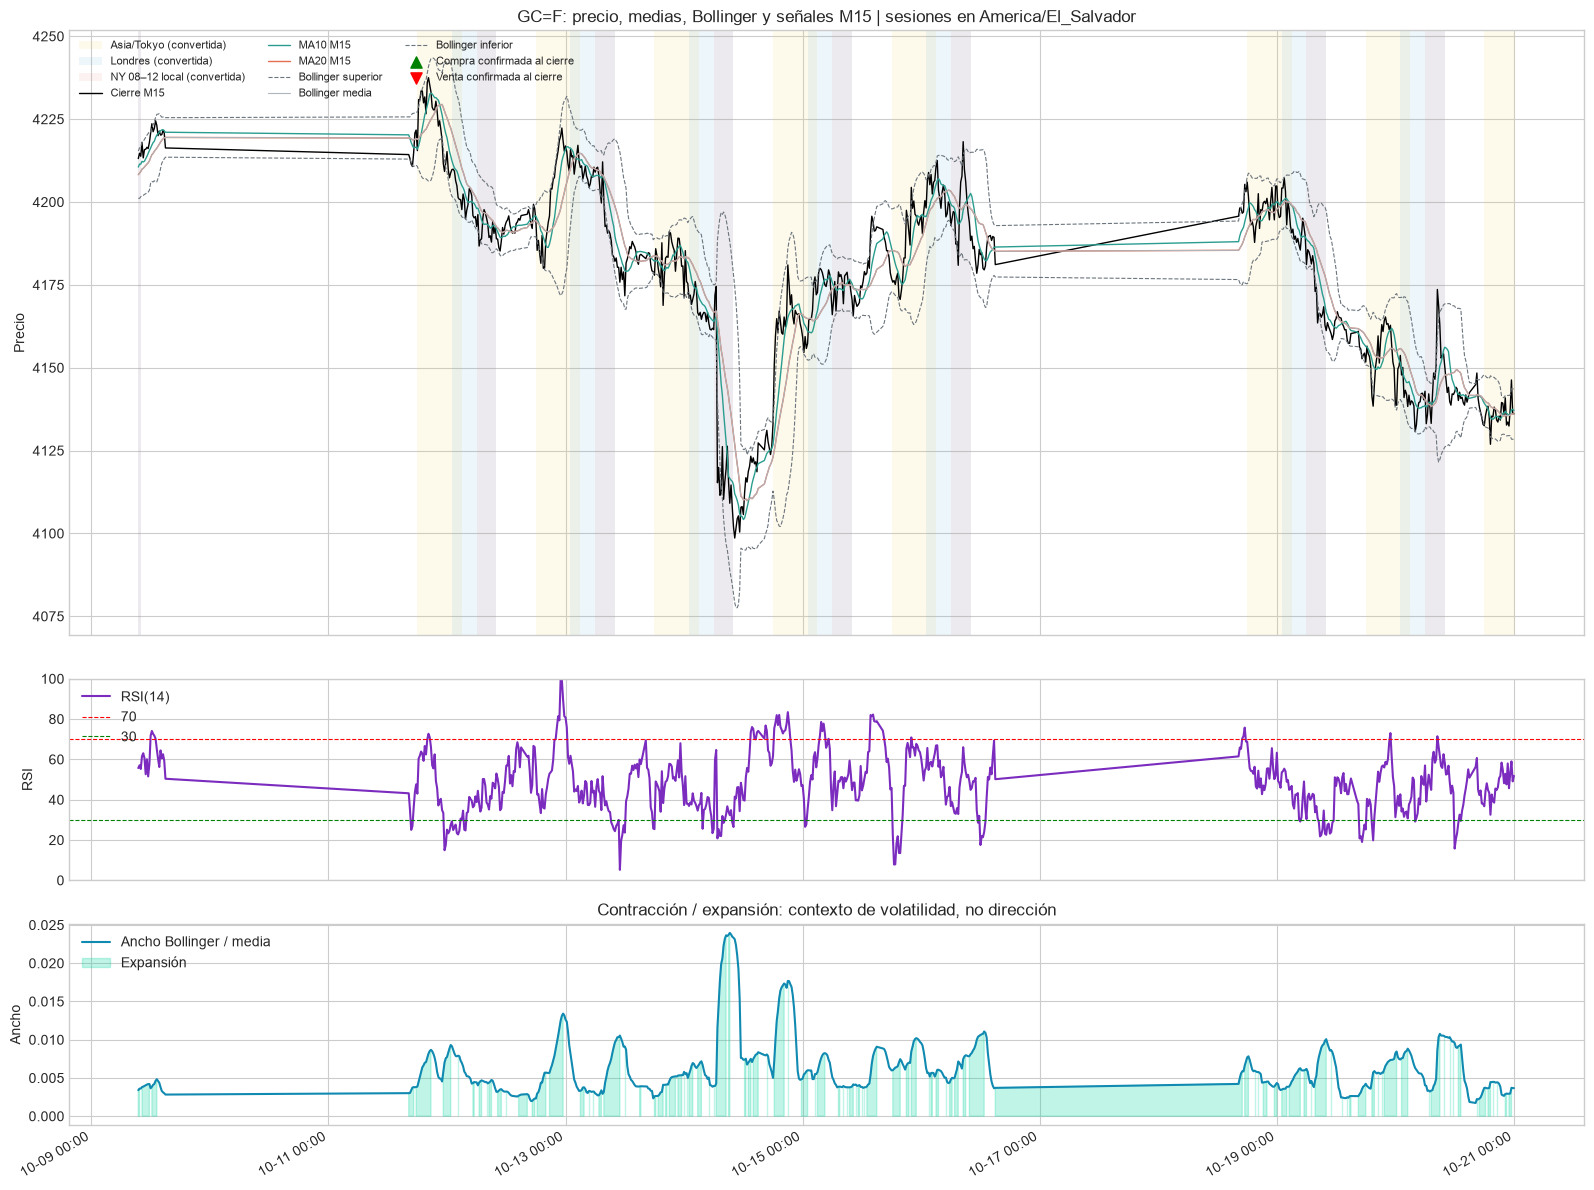

In [8]:
def shade_boolean_intervals(ax, x: pd.Series, mask: pd.Series, color: str, alpha: float, label: str) -> None:
    times = pd.DatetimeIndex(x)
    values = np.asarray(mask.fillna(False), dtype=bool)
    if len(times) == 0:
        return
    step = pd.Timedelta(minutes=15)
    starts = np.flatnonzero(values & np.r_[True, ~values[:-1]])
    ends = np.flatnonzero(values & np.r_[~values[1:], True])
    for number, (start, end) in enumerate(zip(starts, ends)):
        ax.axvspan(times[start], times[end] + step, color=color, alpha=alpha, label=label if number == 0 else None, linewidth=0)

plot_data = m15.tail(min(len(m15), 700)).copy()
x = plot_data['close_time'].dt.tz_convert(TZ_LOCAL)
fig, (ax_price, ax_rsi, ax_width) = plt.subplots(3, 1, figsize=(16, 12), sharex=True, gridspec_kw={'height_ratios': [3, 1, 1]})
if SHOW_ASIA:
    shade_boolean_intervals(ax_price, x, plot_data['session_asia'], '#f4d35e', 0.12, 'Asia/Tokyo (convertida)')
if SHOW_LONDON:
    shade_boolean_intervals(ax_price, x, plot_data['session_london'], '#4ea8de', 0.10, 'Londres (convertida)')
if SHOW_NEW_YORK:
    shade_boolean_intervals(ax_price, x, plot_data['session_new_york'], '#f28482', 0.10, 'NY 08–12 local (convertida)')

ax_price.plot(x, plot_data['Close'], color='black', linewidth=1, label='Cierre M15')
ax_price.plot(x, plot_data['ma_fast'], color='#2a9d8f', linewidth=1, label=f'MA{MA_FAST} M15')
ax_price.plot(x, plot_data['ma_slow'], color='#e76f51', linewidth=1, label=f'MA{MA_SLOW} M15')
ax_price.plot(x, plot_data['bb_upper'], color='#6c757d', linewidth=0.8, linestyle='--', label='Bollinger superior')
ax_price.plot(x, plot_data['bb_mid'], color='#adb5bd', linewidth=0.8, label='Bollinger media')
ax_price.plot(x, plot_data['bb_lower'], color='#6c757d', linewidth=0.8, linestyle='--', label='Bollinger inferior')
buys = plot_data['state'].eq('COMPRA_CONFIRMADA')
sells = plot_data['state'].eq('VENTA_CONFIRMADA')
ax_price.scatter(x[buys], plot_data.loc[buys, 'Low'], marker='^', color='green', s=65, label='Compra confirmada al cierre', zorder=5)
ax_price.scatter(x[sells], plot_data.loc[sells, 'High'], marker='v', color='red', s=65, label='Venta confirmada al cierre', zorder=5)
ax_price.set_title(f'{TICKER}: precio, medias, Bollinger y señales M15 | sesiones en America/El_Salvador')
ax_price.set_ylabel('Precio')
ax_price.legend(loc='upper left', ncols=3, fontsize=8)

ax_rsi.plot(x, plot_data['rsi'], color='#7b2cbf', label=f'RSI({RSI_PERIOD})')
ax_rsi.axhline(RSI_BUY_MAX, color='red', linestyle='--', linewidth=0.8, label=f'{RSI_BUY_MAX:g}')
ax_rsi.axhline(RSI_SELL_MIN, color='green', linestyle='--', linewidth=0.8, label=f'{RSI_SELL_MIN:g}')
ax_rsi.set_ylim(0, 100)
ax_rsi.set_ylabel('RSI')
ax_rsi.legend(loc='upper left')

ax_width.plot(x, plot_data['bb_width'], color='#118ab2', label='Ancho Bollinger / media')
ax_width.fill_between(x, 0, plot_data['bb_width'], where=plot_data['bb_expanding'].fillna(False).to_numpy(), color='#06d6a0', alpha=0.25, label='Expansión')
ax_width.set_ylabel('Ancho')
ax_width.set_title('Contracción / expansión: contexto de volatilidad, no dirección')
ax_width.legend(loc='upper left')
ax_width.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M', tz=TZ_LOCAL))
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## 10. Backtest opcional y validación cronológica

El backtest entra en la apertura de la barra siguiente a la señal. Usa el último swing H1 confirmado más un margen ATR para el stop y un múltiplo de riesgo configurable para el objetivo. Si no hay swing utilizable, no inventa un stop y omite esa entrada. Si stop y objetivo aparecen tocados en la misma vela, asume primero el stop (criterio conservador).

El conjunto se separa por tiempo: desarrollo primero y prueba al final. No se mezclan velas aleatoriamente; los indicadores pueden usar historia anterior al segmento de prueba como contexto disponible. Comisión, deslizamiento y spread son aproximaciones en unidades de precio. El resultado en R no es dinero real y no contempla contrato/valor del punto específicos del bróker. El backtest no garantiza resultados futuros.

In [9]:
def backtest(frame: pd.DataFrame, signal_column: str, start: int, end: int) -> pd.DataFrame:
    trades = []
    index = max(start, 0)
    end = min(end, len(frame))
    next_available = index
    while index < end - 1:
        if index < next_available or not bool(frame.iloc[index][signal_column]):
            index += 1
            continue
        signal = frame.iloc[index]
        direction = 1 if signal['h1_trend'] == 'ALCISTA' else -1
        entry_index = index + 1
        entry_bar = frame.iloc[entry_index]
        entry = float(entry_bar['Open'])
        atr_value = float(signal['atr'])
        swing = signal['h1_last_swing_low'] if direction == 1 else signal['h1_last_swing_high']
        if not np.isfinite(atr_value) or not np.isfinite(swing):
            index += 1
            continue
        stop = float(swing) - STOP_ATR_BUFFER * atr_value if direction == 1 else float(swing) + STOP_ATR_BUFFER * atr_value
        risk = direction * (entry - stop)
        if not np.isfinite(risk) or risk <= 0:
            index += 1
            continue
        target = entry + direction * TARGET_R_MULTIPLE * risk
        exit_price = None
        exit_index = None
        exit_reason = None
        for bar_index in range(entry_index, end):
            bar = frame.iloc[bar_index]
            stop_hit = bar['Low'] <= stop if direction == 1 else bar['High'] >= stop
            target_hit = bar['High'] >= target if direction == 1 else bar['Low'] <= target
            if stop_hit:
                exit_price, exit_index, exit_reason = stop, bar_index, 'stop'
                break
            if target_hit:
                exit_price, exit_index, exit_reason = target, bar_index, 'objetivo'
                break
        if exit_index is None:
            # No se liquida artificialmente una operación abierta al final del segmento.
            break
        spread_cost = float(frame.iloc[exit_index]['spread_price'])
        round_trip_cost = spread_cost + 2 * (COMMISSION_PER_SIDE_PRICE_EQUIV + SLIPPAGE_PER_SIDE_PRICE_EQUIV)
        gross_r = direction * (float(exit_price) - entry) / risk
        net_r = gross_r - round_trip_cost / risk
        trades.append({
            'signal_time': signal['decision_time_local'],
            'entry_time': entry_bar['bar_open_utc'],
            'exit_time': frame.iloc[exit_index]['bar_open_utc'],
            'side': 'LONG' if direction == 1 else 'SHORT',
            'entry_price': entry, 'stop': stop, 'target': target,
            'exit_price': float(exit_price), 'exit_reason': exit_reason,
            'risk_price_units': risk, 'gross_R': gross_r, 'net_R': net_r,
        })
        next_available = exit_index + 1
        index = next_available
    return pd.DataFrame(trades)

def performance_summary(trades: pd.DataFrame, label: str) -> dict:
    if trades.empty:
        return {'segmento': label, 'operaciones': 0, 'aciertos_%': np.nan, 'promedio_R': np.nan, 'profit_factor': np.nan, 'drawdown_max_R': np.nan}
    returns = trades['net_R'].astype(float)
    gains = returns[returns > 0].sum()
    losses = -returns[returns < 0].sum()
    equity_r = returns.cumsum()
    drawdown = equity_r - equity_r.cummax().clip(lower=0)
    return {
        'segmento': label,
        'operaciones': len(trades),
        'aciertos_%': 100 * float((returns > 0).mean()),
        'promedio_R': float(returns.mean()),
        'profit_factor': float(gains / losses) if losses > 0 else (math.inf if gains > 0 else np.nan),
        'drawdown_max_R': float(-drawdown.min()),
    }

if USE_BACKTEST:
    split_at = int(len(m15) * (1 - TEST_FRACTION))
    if split_at < 1 or len(m15) - split_at < 2:
        raise ValueError('No hay suficientes velas para la división cronológica; reduce TEST_FRACTION o consigue más datos permitidos por yfinance.')
    # Combinar compras/ventas mantiene una sola posición abierta por vez.
    m15['any_signal'] = m15['buy_signal'] | m15['sell_signal']
    m15['any_signal_expansion'] = m15['buy_with_expansion'] | m15['sell_with_expansion']
    train_trades = backtest(m15, 'any_signal', 0, split_at)
    test_trades = backtest(m15, 'any_signal', split_at, len(m15))
    train_trades_expansion = backtest(m15, 'any_signal_expansion', 0, split_at)
    test_trades_expansion = backtest(m15, 'any_signal_expansion', split_at, len(m15))
    metrics = pd.DataFrame([
        performance_summary(train_trades, 'Desarrollo (sin exigir expansión)'),
        performance_summary(test_trades, 'Prueba cronológica (sin exigir expansión)'),
        performance_summary(train_trades_expansion, 'Desarrollo (exigiendo expansión)'),
        performance_summary(test_trades_expansion, 'Prueba cronológica (exigiendo expansión)'),
    ])
    print(f'División cronológica: desarrollo hasta {m15.iloc[split_at - 1]["close_time"]}; prueba desde {m15.iloc[split_at]["close_time"]}.')
    print(f'Costos aplicados: spread={spread_source}; comisión por lado={COMMISSION_PER_SIDE_PRICE_EQUIV}; deslizamiento por lado={SLIPPAGE_PER_SIDE_PRICE_EQUIV} unidades de precio.')
    display(metrics)
    if not test_trades.empty:
        test_trades = test_trades.copy()
        test_trades['equity_R'] = test_trades['net_R'].cumsum()
        test_trades['drawdown_R'] = test_trades['equity_R'] - test_trades['equity_R'].cummax().clip(lower=0)
        fig, (ax_equity, ax_drawdown) = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
        ax_equity.plot(test_trades['exit_time'], test_trades['equity_R'], color='#2a9d8f')
        ax_equity.set_title('Prueba cronológica: resultado acumulado (R)')
        ax_equity.set_ylabel('R acumulado')
        ax_drawdown.fill_between(test_trades['exit_time'], test_trades['drawdown_R'], 0, color='#e76f51', alpha=0.35)
        ax_drawdown.set_title('Drawdown (R)')
        ax_drawdown.set_ylabel('Drawdown R')
        fig.tight_layout()
        plt.show()
        display(test_trades.tail(20))
    else:
        print('La prueba no produjo operaciones cerradas. No se calculan métricas ni gráfico de equity.')
else:
    print('Backtest deshabilitado por configuración.')

División cronológica: desarrollo hasta 2026-09-30 14:00:00+00:00; prueba desde 2026-09-30 14:15:00+00:00.
Costos aplicados: spread=sin configurar; filtro de seguridad bloquea señales operables; comisión por lado=0.0; deslizamiento por lado=0.0 unidades de precio.


,segmento,operaciones,aciertos_%,promedio_R,profit_factor,drawdown_max_R
0,Desarrollo (sin exigir expansión),0,NaN,NaN,NaN,NaN
1,Prueba cronológica (sin exigir expansión),0,NaN,NaN,NaN,NaN
2,Desarrollo (exigiendo expansión),0,NaN,NaN,NaN,NaN
3,Prueba cronológica (exigiendo expansión),0,NaN,NaN,NaN,NaN


La prueba no produjo operaciones cerradas. No se calculan métricas ni gráfico de equity.


## 11. Resumen de resultados y limitaciones

1. Revisa la última interpretación y las razones verificables en la tabla. `NO_OPERAR` por spread sin configurar es intencional: ingresa una estimación propia o un archivo Bid/Ask confiable antes de evaluar operabilidad.
2. Comprueba que `GC=F`, las fechas, las sesiones convertidas y la fuente de costos corresponden a tu caso. El futuro no necesariamente replica el CFD XAUUSD y Yahoo no proporciona el spread histórico del bróker.
3. La prueba es solo sobre la historia disponible de yfinance; su límite intradía impide inferir rendimiento de varios años con M15. El resultado no incluye automáticamente interrupciones, financiación, tamaño de contrato, valor por punto, reglas de ejecución ni otros costos del bróker.
4. Los stops/objetivos son parámetros mecánicos configurables, no valores prescritos por un artículo ni recomendaciones de riesgo. Las salidas en R son unidades de riesgo hipotéticas, no ganancias monetarias.
5. Un backtest es una evaluación histórica sujeta a calidad de datos, supuestos de ejecución y sobreajuste. No garantiza resultados futuros. No se generan órdenes ni se presentan señales como predicciones garantizadas.